In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
log_returns = pd.read_csv("../data/processed/log_returns.csv", parse_dates=True, index_col=0)

stocks = log_returns.drop(columns="^NSEI")
index_returns = log_returns["^NSEI"]

mu = stocks.mean() * 252
cov = stocks.cov() * 252

print(mu.round(4))
print(cov.round(4))

HDFCBANK.NS     0.0749
ITC.NS          0.1901
RELIANCE.NS     0.1189
SUNPHARMA.NS    0.3097
TCS.NS          0.1495
dtype: float64
              HDFCBANK.NS  ITC.NS  RELIANCE.NS  SUNPHARMA.NS  TCS.NS
HDFCBANK.NS        0.0748  0.0213       0.0360        0.0187  0.0212
ITC.NS             0.0213  0.0675       0.0242        0.0201  0.0158
RELIANCE.NS        0.0360  0.0242       0.0881        0.0244  0.0283
SUNPHARMA.NS       0.0187  0.0201       0.0244        0.0649  0.0174
TCS.NS             0.0212  0.0158       0.0283        0.0174  0.0599


In [3]:
n = len(stocks.columns)
w = np.ones(n) / n

port_return = w @ mu
port_vol = np.sqrt(w @ cov @ w)
port_sharpe = port_return / port_vol

print("Weights:", w)
print("Return:", round(port_return, 4))
print("Volatility:", round(port_vol, 4))
print("Sharpe:", round(port_sharpe, 4))

Weights: [0.2 0.2 0.2 0.2 0.2]
Return: 0.1686
Volatility: 0.18
Sharpe: 0.9369


In [4]:
annual_vol = stocks.std() * np.sqrt(252)
print("Individual stock volatilities:")
print(annual_vol.round(4))
print("\nEqual-weight portfolio volatility:", round(port_vol, 4))

Individual stock volatilities:
HDFCBANK.NS     0.2734
ITC.NS          0.2599
RELIANCE.NS     0.2968
SUNPHARMA.NS    0.2547
TCS.NS          0.2447
dtype: float64

Equal-weight portfolio volatility: 0.18


In [5]:
np.random.seed(42)
n_portfolios = 10000

results = []
for _ in range(n_portfolios):
    w = np.random.random(n)
    w = w / w.sum()
    ret = w @ mu
    vol = np.sqrt(w @ cov @ w)
    results.append([ret, vol, ret / vol] + list(w))

columns = ["Return", "Volatility", "Sharpe"] + list(stocks.columns)
sim = pd.DataFrame(results, columns=columns)
sim.head()

,Return,Volatility,Sharpe,HDFCBANK.NS,ITC.NS,RELIANCE.NS,SUNPHARMA.NS,TCS.NS
0,0.179438,0.188654,0.951150,0.133197,0.338101,0.260318,0.212900,0.055485
1,0.174810,0.196279,0.890622,0.065285,0.024308,0.362501,0.251571,0.296334
2,0.170436,0.203356,0.838117,0.009284,0.437468,0.375464,0.095773,0.082010
3,0.179347,0.186347,0.962439,0.105673,0.175297,0.302353,0.248877,0.167800
4,0.154725,0.185143,0.835708,0.327909,0.074759,0.156568,0.196343,0.244421


In [6]:
best_sharpe = sim.loc[sim["Sharpe"].idxmax()]
min_vol = sim.loc[sim["Volatility"].idxmin()]

print("Best Sharpe portfolio:")
print(best_sharpe.round(4))
print("\nLowest volatility portfolio:")
print(min_vol.round(4))

Best Sharpe portfolio:
Return          0.2601
Volatility      0.2044
Sharpe          1.2724
HDFCBANK.NS     0.0154
ITC.NS          0.1008
RELIANCE.NS     0.0180
SUNPHARMA.NS    0.6756
TCS.NS          0.1903
Name: 3485, dtype: float64

Lowest volatility portfolio:
Return          0.1864
Volatility      0.1748
Sharpe          1.0661
HDFCBANK.NS     0.1563
ITC.NS          0.2365
RELIANCE.NS     0.0665
SUNPHARMA.NS    0.2557
TCS.NS          0.2851
Name: 3816, dtype: float64


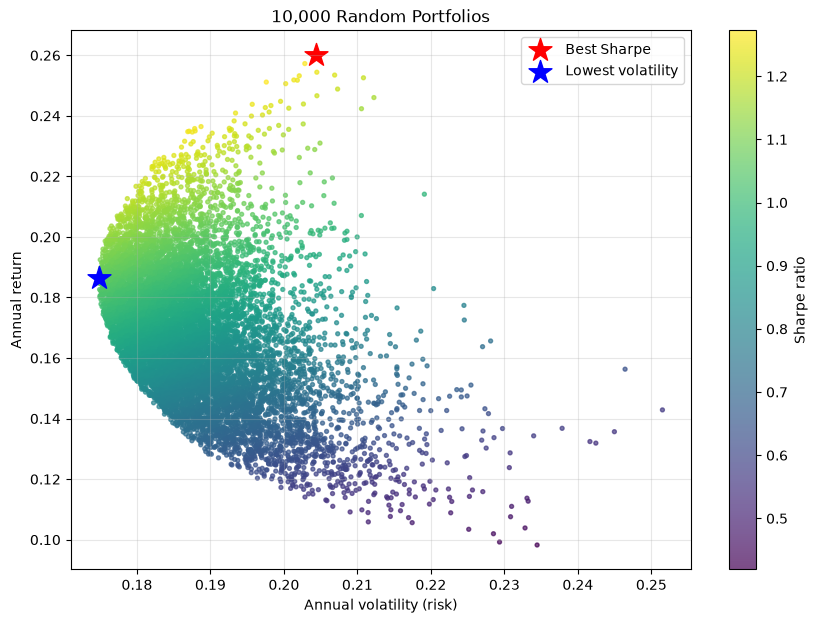

In [7]:
plt.figure(figsize=(10, 7))
sc = plt.scatter(sim["Volatility"], sim["Return"], c=sim["Sharpe"], cmap="viridis", s=8, alpha=0.7)
plt.colorbar(sc, label="Sharpe ratio")

plt.scatter(best_sharpe["Volatility"], best_sharpe["Return"], color="red", marker="*", s=300, label="Best Sharpe")
plt.scatter(min_vol["Volatility"], min_vol["Return"], color="blue", marker="*", s=300, label="Lowest volatility")

plt.title("10,000 Random Portfolios")
plt.xlabel("Annual volatility (risk)")
plt.ylabel("Annual return")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("../reports/figures/portfolio_simulation.png", dpi=150, bbox_inches="tight", facecolor="white")
plt.show()

In [8]:
def performance(w):
    ret = w @ mu
    vol = np.sqrt(w @ cov @ w)
    return ret, vol, ret / vol

w_best = best_sharpe[stocks.columns].values.astype(float)
w_min = min_vol[stocks.columns].values.astype(float)
w_equal = np.ones(n) / n

idx_ret = index_returns.mean() * 252
idx_vol = index_returns.std() * np.sqrt(252)

comparison = pd.DataFrame(
    {
        "Best Sharpe": performance(w_best),
        "Lowest volatility": performance(w_min),
        "Equal weight": performance(w_equal),
        "NIFTY 50 index": (idx_ret, idx_vol, idx_ret / idx_vol),
    },
    index=["Return", "Volatility", "Sharpe"],
).T

print(comparison.round(4))
comparison.to_csv("../data/processed/portfolio_comparison.csv")

                   Return  Volatility  Sharpe
Best Sharpe        0.2601      0.2044  1.2724
Lowest volatility  0.1864      0.1748  1.0661
Equal weight       0.1686      0.1800  0.9369
NIFTY 50 index     0.1351      0.1928  0.7005


In [9]:
sim.to_csv("../data/processed/portfolio_simulation.csv", index=False)

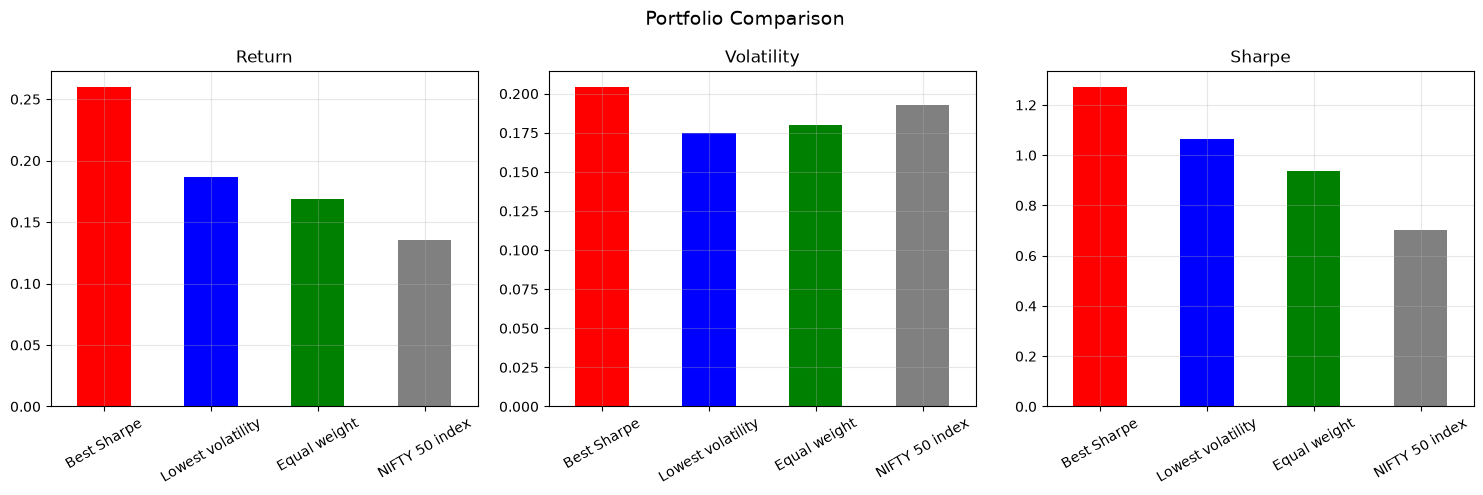

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, metric in zip(axes, ["Return", "Volatility", "Sharpe"]):
    comparison[metric].plot(kind="bar", ax=ax, color=["red", "blue", "green", "gray"])
    ax.set_title(metric)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30)
    ax.grid(alpha=0.3)

plt.suptitle("Portfolio Comparison", fontsize=14)
plt.tight_layout()
plt.savefig("../reports/figures/portfolio_comparison.png", dpi=150, bbox_inches="tight", facecolor="white")
plt.show()

In [11]:
train = stocks.loc["2020-01-01":"2023-12-31"]
test = stocks.loc["2024-01-01":"2024-12-31"]

mu_train = train.mean() * 252
cov_train = train.cov() * 252

print("Train rows:", len(train), " Test rows:", len(test))

Train rows: 991  Test rows: 246


In [12]:
np.random.seed(42)
best_w, best_s = None, -np.inf

for _ in range(10000):
    w = np.random.random(n)
    w = w / w.sum()
    ret = w @ mu_train
    vol = np.sqrt(w @ cov_train @ w)
    s = ret / vol
    if s > best_s:
        best_s, best_w = s, w

print("Weights chosen on 2020-2023:")
print(pd.Series(best_w, index=stocks.columns).round(4))
print("Training Sharpe:", round(best_s, 4))

Weights chosen on 2020-2023:
HDFCBANK.NS     0.0196
ITC.NS          0.2595
RELIANCE.NS     0.0438
SUNPHARMA.NS    0.5863
TCS.NS          0.0907
dtype: float64
Training Sharpe: 1.1694


In [13]:
def test_performance(w, data):
    daily = data @ w
    ret = daily.mean() * 252
    vol = daily.std() * np.sqrt(252)
    return ret, vol, ret / vol

w_equal = np.ones(n) / n

honest = pd.DataFrame(
    {
        "Train-chosen weights": test_performance(best_w, test),
        "Equal weights": test_performance(w_equal, test),
        "NIFTY 50 index": (
            index_returns.loc["2024"].mean() * 252,
            index_returns.loc["2024"].std() * np.sqrt(252),
            index_returns.loc["2024"].mean() * 252 / (index_returns.loc["2024"].std() * np.sqrt(252)),
        ),
    },
    index=["Return", "Volatility", "Sharpe"],
).T

print(honest.round(4))
honest.to_csv("../data/processed/honest_test_2024.csv")

                      Return  Volatility  Sharpe
Train-chosen weights  0.2762      0.1404  1.9672
Equal weights         0.1187      0.1255  0.9460
NIFTY 50 index        0.0864      0.1413  0.6120
